## Assignment 03: Neural Networks

**Index No:** 230186E  
**Name:** Fernando W. H. D.  
**GitHub:** https://github.com/himashafdo/EN3160-A03.git

### Question 01

Epoch 1 / 10 , Loss : 1.8985319283008575 
Epoch 2 / 10 , Loss : 1.7176041120290757 
Epoch 3 / 10 , Loss : 1.6499241502285005 
Epoch 4 / 10 , Loss : 1.6009520071744918 
Epoch 5 / 10 , Loss : 1.5591959162950515 
Epoch 6 / 10 , Loss : 1.524693330168724 
Epoch 7 / 10 , Loss : 1.4934421377182008 
Epoch 8 / 10 , Loss : 1.467068625330925 
Epoch 9 / 10 , Loss : 1.4429711796045304 
Epoch 10 / 10 , Loss : 1.4222800461053848 


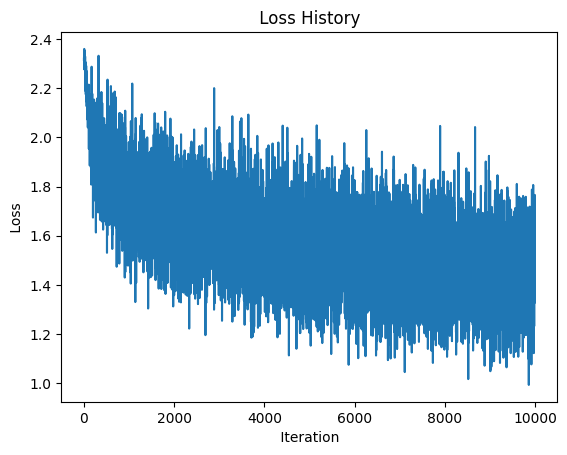

 Training accuracy : 52.07%
Test accuracy: 47.96%


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib . pyplot as plt

# 1. Dataloading
transform = transforms.Compose ([transforms.ToTensor() ,transforms.Normalize ((0.5,0.5,0.5) , (0.5,0.5,0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10( root= './data' , train=True ,download=True , transform=transform )
trainloader = torch.utils.data.DataLoader( trainset , batch_size=batch_size ,shuffle=True , num_workers=2)
testset = torchvision.datasets.CIFAR10( root= './data' , train=False ,download=True , transform=transform )
testloader = torch.utils.data.DataLoader( testset , batch_size=batch_size ,shuffle=False , num_workers=2)

classes = ( ' plane ' , ' car ' , ' bird ' , ' cat ' ,' deer ' , ' dog ' , ' f rog ' , ' horse ' , ' ship ' , ' truck ')


# 2. Define Network Parameters
Din = 3*32*32  # Input size(flattened CIFAR−10 image size)

K = 10  # Output size (number of classes in CIFAR−10)
std = 1e-2 #=========================================
H = 100 #hidden layer nodes

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-1 # Learning rate #===================================
lr_decay = 0.9 # Learning rate decay
reg = 0 # Regularization
loss_history = []

#helper functions I defined 
def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def softmax(logits):
    logits = logits - logits.max(dim=1, keepdim=True).values
    e = torch.exp(logits)
    return e / e.sum(dim=1, keepdim=True)

# 3. Training Loop
for t in range( iterations ):
    running_loss = 0.0
    for i , data in enumerate( trainloader, 0 ):

        # Get inputs and labe l s
        inputs, labels = data
        Ntr = inputs . shape [0]  # Batch size

        x_train = inputs.view ( Ntr , -1) # Flatten input to ( Ntr , Din )
        y_train_onehot = nn.functional.one_hot ( labels , K) . float ( ) # Convert labels to one−hot
        
        # Forward pass
        #y_pred = x_train.mm(w) + b # Output layer activation

        h = sigmoid(x_train.mm(w1) + b1)
        logits = h.mm(w2) + b2
        p = softmax(logits)


        # Loss calculation (Mean Squared Error with regularization )
        #loss = (1 / Ntr ) * torch.sum( ( y_pred - y_train_onehot ) ** 2) + reg * torch.sum(w ** 2)
        loss = -(1/Ntr) * torch.sum(y_train_onehot * torch.log(p + 1e-12))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # dy_pred = (2.0 / Ntr ) * (y_pred - y_train_onehot)
        # dw = x_train.t ( ) .mm( dy_pred ) + reg * w
        # db = dy_pred.sum(dim=0)

        dlogits = (p - y_train_onehot) / Ntr
        dw2 = h.t().mm(dlogits)
        db2 = dlogits.sum(dim=0)
        dz1 = dlogits.mm(w2.t()) * h * (1 - h)
        dw1 = x_train.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t%1 == 0:
        print (f"Epoch { t + 1 } / { iterations } , Loss : { running_loss / len ( trainloader) } " )


    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
plt.plot (loss_history)
plt.title ( " Loss History " )
plt.xlabel ( " Iteration " )
plt.ylabel ( " Loss " )
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad ( ) :
    for data in trainloader :
        inputs , labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view ( Ntr , -1)
        y_train_onehot = nn.functional.one_hot (labels , K).float()

        # Forward pass
        y_train_pred = sigmoid(x_train.mm(w1) + b1).mm(w2) + b2

        predicted_train = torch.argmax ( y_train_pred , dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print (f" Training accuracy : {train_acc:.2f}%" )

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad ( ) :
    for data in testloader :
        inputs , labels = data
        Nte = inputs.shape [0]
        x_test = inputs.view( Nte , -1)
        y_test_onehot = nn.functional.one_hot( labels ,K).float()

        # Forward pass
        y_test_pred = sigmoid(x_test.mm(w1) + b1).mm(w2) + b2
        predicted_test = torch.argmax ( y_test_pred , dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print (f"Test accuracy: {test_acc:.2f}%")